# Bank Marketing Prediction Using Supervised Machine Learning

## Mini Project - Machine Learning

## 1. Problem statement

> **Given** information about a bank customer and the history of earlier marketing contact with them,
> **predict** whether the customer will subscribe to a term deposit (`y = yes`) or not (`y = no`).

* **Type of problem:** supervised learning, binary classification.
* **Target variable:** `y` → encoded as `yes = 1`, `no = 0`.
* **Important design decision:** the model is meant to be used **before** a customer is called.
  Therefore it may only use information that is available *before* the call. The column `duration`
  (length of the last call) is known only *after* the call, so it is **excluded** from the model (explained in Section 9).
* **Challenge:** the classes are imbalanced (far more `no` than `yes`), so **accuracy alone is misleading**. We therefore also use precision, recall, F1-score, ROC-AUC and average precision.

Steps we follow: Load data -> Clean data -> Explore (graphs) -> Split into train/test -> Train models -> Compare -> Predict

## 3. Dataset source and description

* **Source:** UCI Machine Learning Repository, *Bank Marketing* dataset (ID 222) —
  <https://archive.ics.uci.edu/dataset/222/bank+marketing>
* **File used:** `bank-full.csv` (all 45,211 examples, 16 input columns + target `y`).
  The original file uses `;` as separator; the copy shipped with this project is saved with standard commas so `pd.read_csv("bank-full.csv")` works. The values are unchanged.
* **Origin:** direct marketing (phone-call) campaigns of a Portuguese banking institution.

| # | Column | Type | Meaning |
|---|--------|------|---------|
| 1 | `age` | numeric | Age of the customer |
| 2 | `job` | categorical | Type of job (admin., blue-collar, management, retired, student, ...) |
| 3 | `marital` | categorical | Marital status |
| 4 | `education` | categorical | Education level (primary, secondary, tertiary, unknown) |
| 5 | `default` | categorical | Has credit in default? |
| 6 | `balance` | numeric | Average yearly balance (euros) |
| 7 | `housing` | categorical | Has a housing loan? |
| 8 | `loan` | categorical | Has a personal loan? |
| 9 | `contact` | categorical | Contact communication type (cellular, telephone, unknown) |
| 10 | `day` | numeric | Day of month of the last contact |
| 11 | `month` | categorical | Month of the last contact |
| 12 | `duration` | numeric | Duration of the last contact in seconds (**known only after the call**) |
| 13 | `campaign` | numeric | Number of contacts during *this* campaign for this client |
| 14 | `pdays` | numeric | Days since the client was last contacted in a *previous* campaign; **`-1` = not previously contacted** |
| 15 | `previous` | numeric | Number of contacts before this campaign |
| 16 | `poutcome` | categorical | Outcome of the previous campaign (success, failure, other, unknown) |
| 17 | `y` | target | Did the client subscribe to a term deposit? (yes / no) |

## 4. Library imports

In [ ]:
%pip install seaborn
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, roc_curve, precision_recall_curve)

# Reproducibility: one global seed used everywhere
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (8, 5)

# Show everything in tables, but keep scikit-learn FutureWarnings quiet
pd.set_option("display.max_columns", 50)
warnings.filterwarnings("ignore", category=FutureWarning)

import sklearn
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

## 5. Dataset loading

The notebook reads the **local** file `bank-full.csv` (relative path). It does **not** download anything.
We also store a SHA-256 fingerprint of the file now and compare it again at the very end to **prove that the original dataset was never modified**.

In [18]:
DATA_PATH = Path("bank-full.csv")          # relative path: file must sit next to this notebook
PROCESSED_PATH = Path("processed_bank_marketing.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError("bank-full.csv not found. Place it in the same folder as this notebook.")

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

raw_hash_before = file_sha256(DATA_PATH)

df_raw = pd.read_csv(DATA_PATH)            # delivered file is comma-separated

# Safety check: if someone swapped in the original semicolon file, everything would be in 1 column
if df_raw.shape[1] == 1:
    raise ValueError("Only one column was read. The file looks semicolon-separated: use pd.read_csv('bank-full.csv', sep=';').")

df = df_raw.copy()                         # df_raw stays untouched as the 'original' in memory
print("Loaded:", DATA_PATH, "->", df.shape)
print("SHA-256 of bank-full.csv (before):", raw_hash_before)
df.head()

Loaded: bank-full.csv -> (45211, 17)
SHA-256 of bank-full.csv (before): b44507c26634736d4a0619ec2d7c4b6ff56a2c63cbeb5176d3134e7b25e416f0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 6. Initial dataset inspection

In [4]:
print("Dimensions (rows, columns):", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes.to_string())

Dimensions (rows, columns): (45211, 17)

Column names: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data types:
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str


In [5]:
print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nTotal missing cells:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))

Missing values per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0

Total missing cells: 0
Exact duplicate rows: 0


In [6]:
print("Target class distribution (y):")
tc = df["y"].value_counts()
print(pd.DataFrame({"count": tc, "percent": (tc / len(df) * 100).round(2)}).to_string())

Target class distribution (y):
     count  percent
y                  
no   39922     88.3
yes   5289     11.7


In [7]:
# Numerical feature statistics
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


In [8]:
# Unique values of every categorical feature
cat_cols_raw = [c for c in df.columns if c not in df.select_dtypes(include="number").columns]
for c in cat_cols_raw:
    vals = sorted(df[c].dropna().unique().tolist())
    print(f"{c:10s} ({len(vals):2d} unique): {vals}")

job        (12 unique): ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
marital    ( 3 unique): ['divorced', 'married', 'single']
education  ( 4 unique): ['primary', 'secondary', 'tertiary', 'unknown']
default    ( 2 unique): ['no', 'yes']
housing    ( 2 unique): ['no', 'yes']
loan       ( 2 unique): ['no', 'yes']
contact    ( 3 unique): ['cellular', 'telephone', 'unknown']
month      (12 unique): ['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
poutcome   ( 4 unique): ['failure', 'other', 'success', 'unknown']
y          ( 2 unique): ['no', 'yes']


## 7. Data cleaning

Cleaning is only applied **when justified**. The original `bank-full.csv` is never overwritten; the cleaned/engineered version is saved separately as `processed_bank_marketing.csv`.

Checks performed in this section:
1. Missing-value detection
2. Duplicate-row detection (counted **before** anything is removed)
3. Data-type and value-range validation
4. Inspection of categorical values, including the string `"unknown"`
5. Inspection of numerical distributions
6. Outlier visualisation (**Graph 4**)
7. Target distribution analysis

In [9]:
# 7.1 Missing values
missing = df.isna().sum()
print("Cells that are truly empty (NaN):", int(missing.sum()))

# 7.2 Duplicates -- report BEFORE removing
dup_count = int(df.duplicated().sum())
print("Exact duplicate rows found:", dup_count)
if dup_count > 0:
    df_clean = df.drop_duplicates().reset_index(drop=True)
    print(f"Removed {dup_count} duplicate rows -> {df_clean.shape}")
else:
    df_clean = df.copy()
    print("No duplicates, so no rows were removed ->", df_clean.shape)

Cells that are truly empty (NaN): 0
Exact duplicate rows found: 0
No duplicates, so no rows were removed -> (45211, 17)


In [10]:

expected_numeric = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
expected_categorical = ["job", "marital", "education", "default", "housing", "loan",
                        "contact", "month", "poutcome", "y"]
months_valid = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]

checks = {
    "all expected columns present": set(expected_numeric + expected_categorical) == set(df_clean.columns),
    "numeric columns are numeric": all(pd.api.types.is_numeric_dtype(df_clean[c]) for c in expected_numeric),
    "target only contains yes/no": set(df_clean["y"].unique()) <= {"yes", "no"},
    "age between 18 and 100": df_clean["age"].between(18, 100).all(),
    "day between 1 and 31": df_clean["day"].between(1, 31).all(),
    "month values valid": set(df_clean["month"].unique()) <= set(months_valid),
    "duration >= 0": (df_clean["duration"] >= 0).all(),
    "campaign >= 1": (df_clean["campaign"] >= 1).all(),
    "previous >= 0": (df_clean["previous"] >= 0).all(),
    "pdays is -1 or positive": ((df_clean["pdays"] == -1) | (df_clean["pdays"] > 0)).all(),
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values()), "A data validation check failed - inspect the data before continuing."

PASS  all expected columns present
PASS  numeric columns are numeric
PASS  target only contains yes/no
PASS  age between 18 and 100
PASS  day between 1 and 31
PASS  month values valid
PASS  duration >= 0
PASS  campaign >= 1
PASS  previous >= 0
PASS  pdays is -1 or positive


In [11]:
# 7.4 The string "unknown" is a REAL category value, not an empty cell
cat_features_all = [c for c in expected_categorical if c != "y"]
unk = pd.DataFrame({
    "unknown_count": [(df_clean[c] == "unknown").sum() for c in cat_features_all],
    "unknown_percent": [round((df_clean[c] == "unknown").mean() * 100, 2) for c in cat_features_all],
}, index=cat_features_all)
print("How often the value 'unknown' appears (kept as its own category, NOT treated as missing):")
print(unk[unk.unknown_count > 0].sort_values("unknown_count", ascending=False).to_string())

# pdays sentinel check: -1 should coincide with previous == 0
print("\nCross-check of the pdays sentinel (-1 = not previously contacted):")
print(pd.crosstab(df_clean["pdays"] == -1, df_clean["previous"] == 0,
                  rownames=["pdays == -1"], colnames=["previous == 0"]).to_string())

How often the value 'unknown' appears (kept as its own category, NOT treated as missing):
           unknown_count  unknown_percent
poutcome           36959            81.75
contact            13020            28.80
education           1857             4.11
job                  288             0.64

Cross-check of the pdays sentinel (-1 = not previously contacted):
previous == 0  False  True 
pdays == -1                
False           8257      0
True               0  36954


In [12]:
# 7.5 Numerical distributions: skewness and IQR-based outlier counts (outliers are REPORTED, not removed)
num_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
rows = []
for c in num_cols:
    q1, q3 = df_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df_clean[c] < lo) | (df_clean[c] > hi)).sum())
    rows.append({"feature": c, "skewness": round(df_clean[c].skew(), 2),
                 "IQR lower fence": round(lo, 1), "IQR upper fence": round(hi, 1),
                 "outliers (count)": n_out, "outliers (%)": round(n_out / len(df_clean) * 100, 2)})
outlier_table = pd.DataFrame(rows).set_index("feature")
outlier_table

,skewness,IQR lower fence,IQR upper fence,outliers (count),outliers (%)
feature,,,,,
age,0.68,10.5,70.5,487,1.08
balance,8.36,-1962.0,3462.0,4729,10.46
day,0.09,-11.5,40.5,0,0.00
duration,3.14,-221.0,643.0,3235,7.16
campaign,4.90,-2.0,6.0,3064,6.78
pdays,2.62,-1.0,-1.0,8257,18.26
previous,41.85,0.0,0.0,8257,18.26


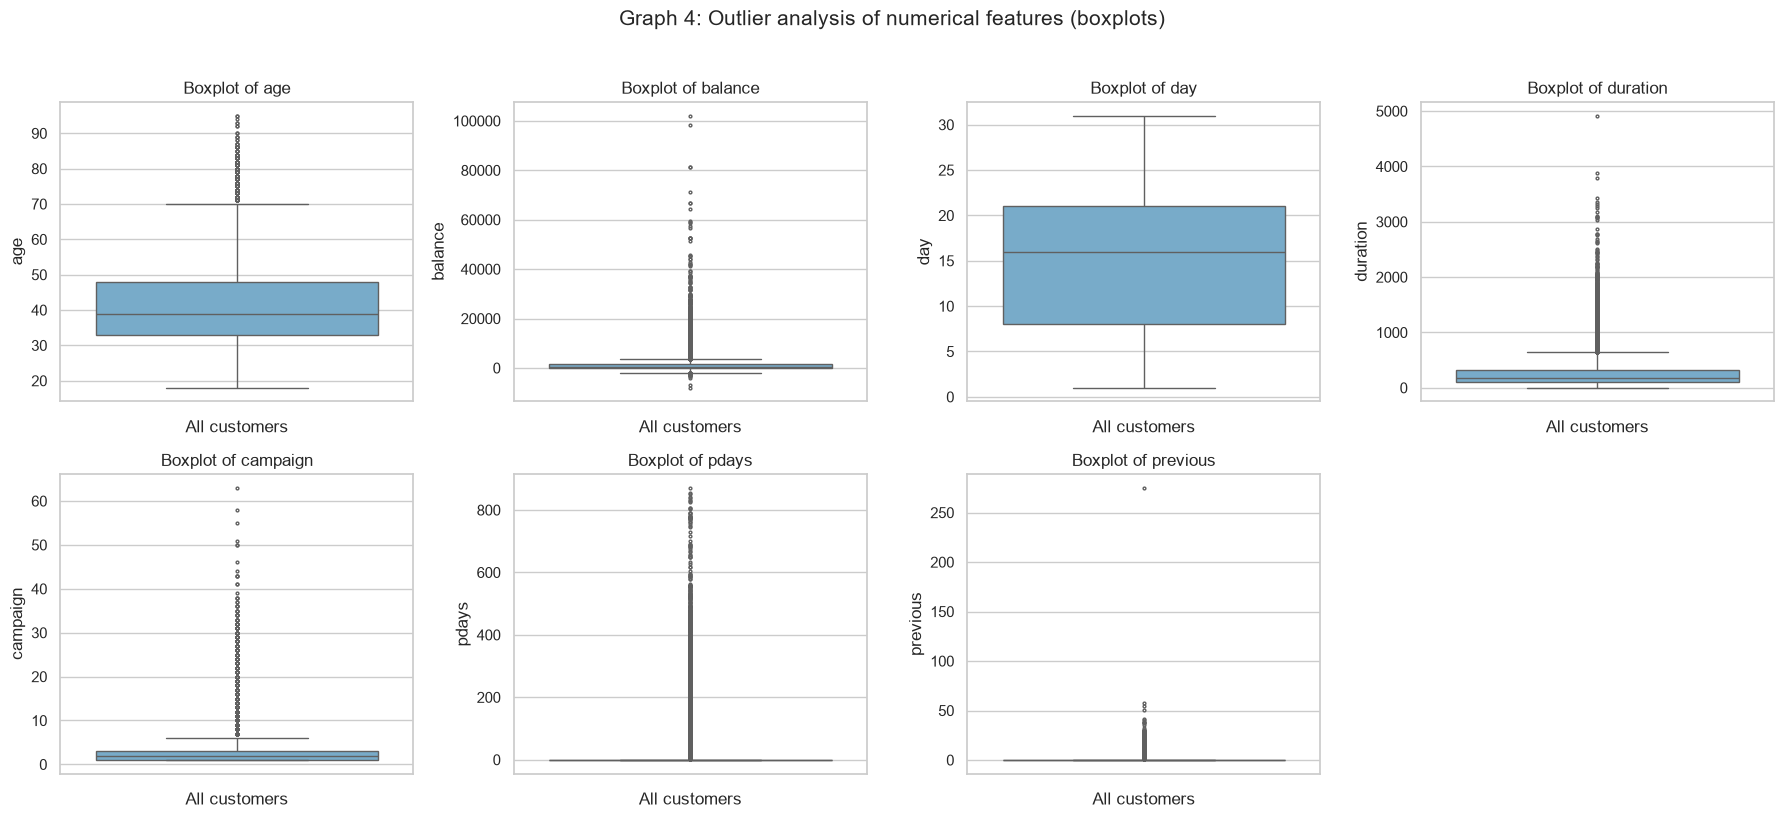

In [13]:
# Graph 4: Outlier analysis using boxplots
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df_clean[c], ax=ax, color="#6baed6", fliersize=2)
    ax.set_title(f"Boxplot of {c}")
    ax.set_ylabel(c)
    ax.set_xlabel("All customers")
axes.ravel()[-1].axis("off")
fig.suptitle("Graph 4: Outlier analysis of numerical features (boxplots)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

**What Graph 4 shows.** Each box covers the middle 50% of values (Q1 to Q3); the line inside is the median; the whiskers extend to 1.5 × IQR; points beyond the whiskers are statistical outliers.
Boxplots only *flag* unusual values — they do not tell us whether the values are errors.

**Decision on outliers.** We looked at the outlier counts in the table above. Large balances, long calls, many contacts, etc. are **plausible real-world values**
(a few wealthy customers, a few very long calls), and the data passed our range checks, so we **do not delete them**.
Note that `pdays` and `previous` show about 18% "outliers" only because most customers share the same value (`-1` and `0`, i.e. never contacted before), which collapses the IQR fences — these are not errors, they are the sentinel meaning described in Section 9.
Instead of deleting anything, we use `StandardScaler` for the linear model, and tree-based models are naturally robust to extreme values.

In [14]:
# 7.6 Target distribution analysis
target_counts = df_clean["y"].value_counts()
imbalance_ratio = target_counts["no"] / target_counts["yes"]
print(f"'no' : {target_counts['no']:,} ({target_counts['no']/len(df_clean):.2%})")
print(f"'yes': {target_counts['yes']:,} ({target_counts['yes']/len(df_clean):.2%})")
print(f"Imbalance ratio (no : yes) = {imbalance_ratio:.2f} : 1")
print(f"A 'dumb' model that always predicts 'no' would already score {target_counts['no']/len(df_clean):.2%} accuracy.")

'no' : 39,922 (88.30%)
'yes': 5,289 (11.70%)
Imbalance ratio (no : yes) = 7.55 : 1
A 'dumb' model that always predicts 'no' would already score 88.30% accuracy.


**Why accuracy alone is not enough here.** If most customers say *no*, a useless model that always answers *no* still gets a very high accuracy but finds **zero** subscribers.
The bank cares about finding the customers who *will* subscribe, so we also measure **recall** (how many real subscribers we find), **precision** (how many of our "yes" predictions are right),
**F1-score** (balance of the two) and ranking quality (**ROC-AUC**, **average precision**). To help the models learn the minority class we also use `class_weight`.

## 8. Exploratory data analysis (EDA)

Graphs 1–3 and 5–7 are generated below (Graph 4 was in Section 7). After every graph, a code cell prints the **actual computed numbers** the graph is based on,
so conclusions come from the data and not from assumptions.

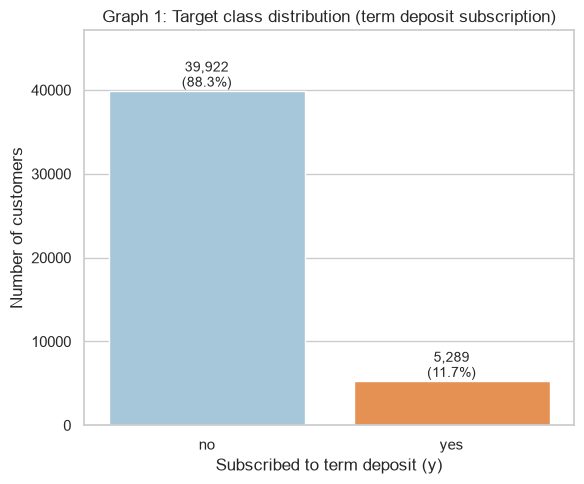

In [15]:
# Graph 1: Target class distribution
fig, ax = plt.subplots(figsize=(6, 5))
order = ["no", "yes"]
sns.countplot(data=df_clean, x="y", order=order, hue="y", hue_order=order,
              palette={"no": "#9ecae1", "yes": "#fd8d3c"}, legend=False, ax=ax)
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{int(h):,}\n({h/len(df_clean):.1%})", (p.get_x() + p.get_width()/2, h),
                    ha="center", va="bottom", fontsize=10)
ax.set_title("Graph 1: Target class distribution (term deposit subscription)")
ax.set_xlabel("Subscribed to term deposit (y)")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, target_counts.max() * 1.18)
plt.tight_layout()
plt.show()

**What Graph 1 shows.** The number of customers in each class. The two bars are clearly of different heights, which means the dataset is **imbalanced**.
The exact counts and percentages are printed on the bars and in Section 7.6. This is why we use class weighting and several evaluation metrics.

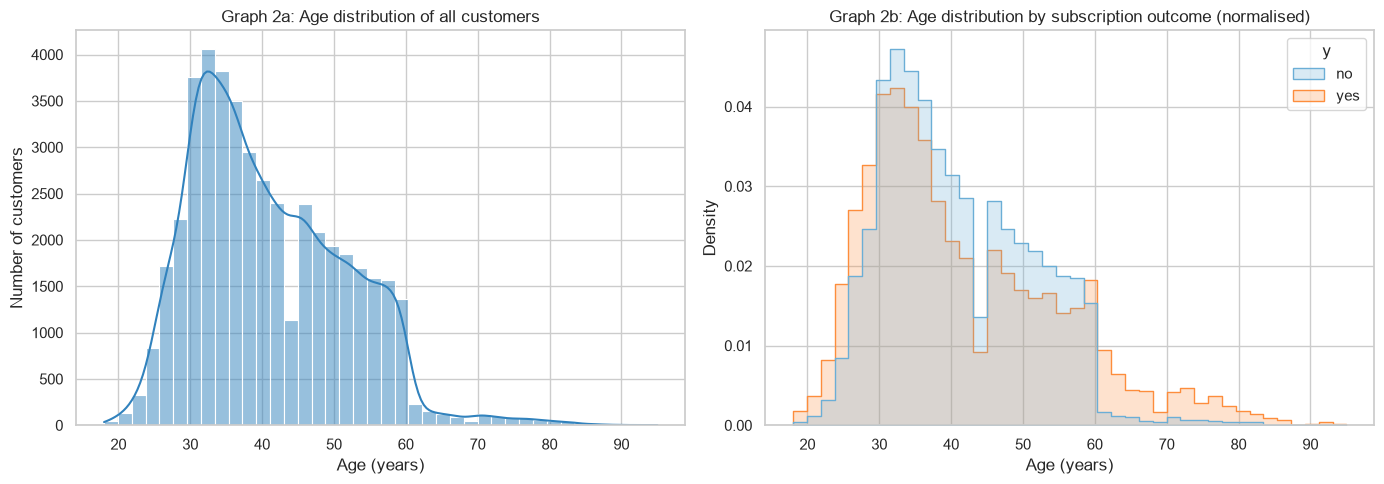

       count   mean    std   min   25%   50%   75%   max
y                                                       
no   39922.0  40.84  10.17  18.0  33.0  39.0  48.0  95.0
yes   5289.0  41.67  13.50  18.0  31.0  38.0  50.0  95.0


In [16]:
# Graph 2: Customer age distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean["age"], bins=40, kde=True, color="#3182bd", ax=axes[0])
axes[0].set_title("Graph 2a: Age distribution of all customers")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of customers")

sns.histplot(data=df_clean, x="age", hue="y", hue_order=["no", "yes"], bins=40, stat="density",
             common_norm=False, element="step", palette={"no": "#6baed6", "yes": "#fd8d3c"}, ax=axes[1])
axes[1].set_title("Graph 2b: Age distribution by subscription outcome (normalised)")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Density")
plt.tight_layout()
plt.show()

print(df_clean.groupby("y")["age"].describe().round(2).to_string())

**What Graph 2 shows.** Left: how many customers there are at each age. Right: the age shapes of customers who said *no* and *yes*, each scaled to the same total area so the two groups can be compared fairly even though *yes* is much smaller.
Where the orange curve is higher than the blue curve, that age range is more common among subscribers than among non-subscribers. The summary statistics printed below the graph give the exact numbers.

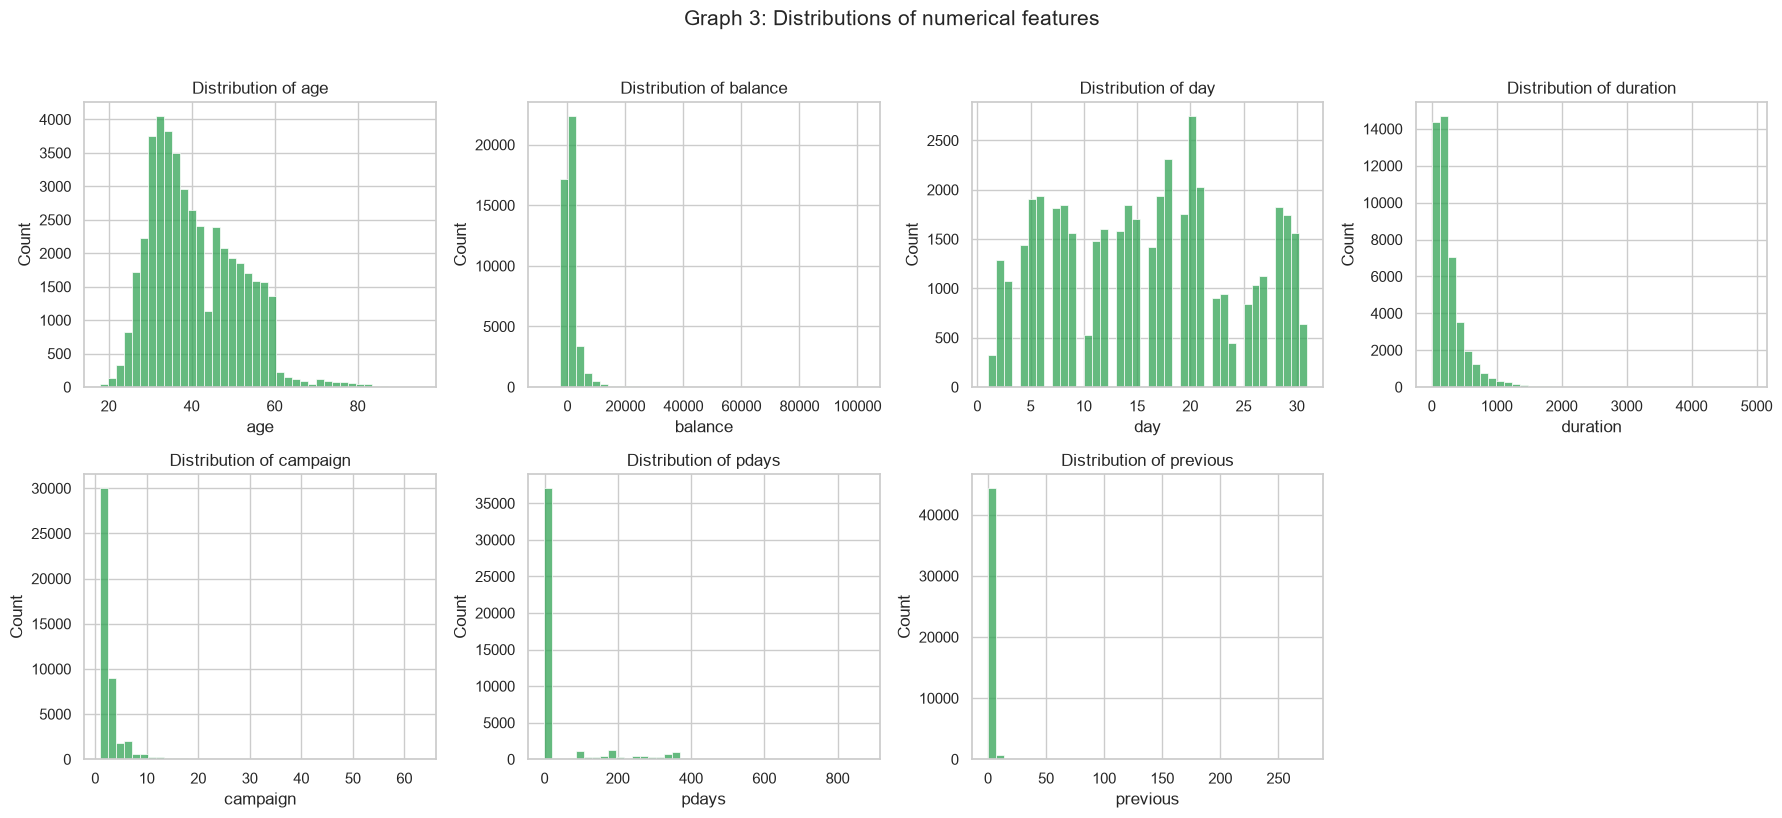

Skewness of each numerical feature (0 = symmetric, large positive = long right tail):
age          0.68
balance      8.36
day          0.09
duration     3.14
campaign     4.90
pdays        2.62
previous    41.85


In [19]:
# Graph 3: Numerical feature distributions
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df_clean[c], bins=40, color="#31a354", ax=ax)
    ax.set_title(f"Distribution of {c}")
    ax.set_xlabel(c)
    ax.set_ylabel("Count")
axes.ravel()[-1].axis("off")
fig.suptitle("Graph 3: Distributions of numerical features", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

print("Skewness of each numerical feature (0 = symmetric, large positive = long right tail):")
print(df_clean[num_cols].skew().round(2).to_string())

**What Graph 3 shows.** A histogram per numerical column: where values are concentrated and how spread out they are.
A long tail to the right (high positive skewness in the printed table) means most customers have small values and a few have very large ones.
`duration` is plotted for exploration only — it will **not** be used as a model input (Section 9). `pdays` shows the `-1` sentinel as a tall bar at -1.

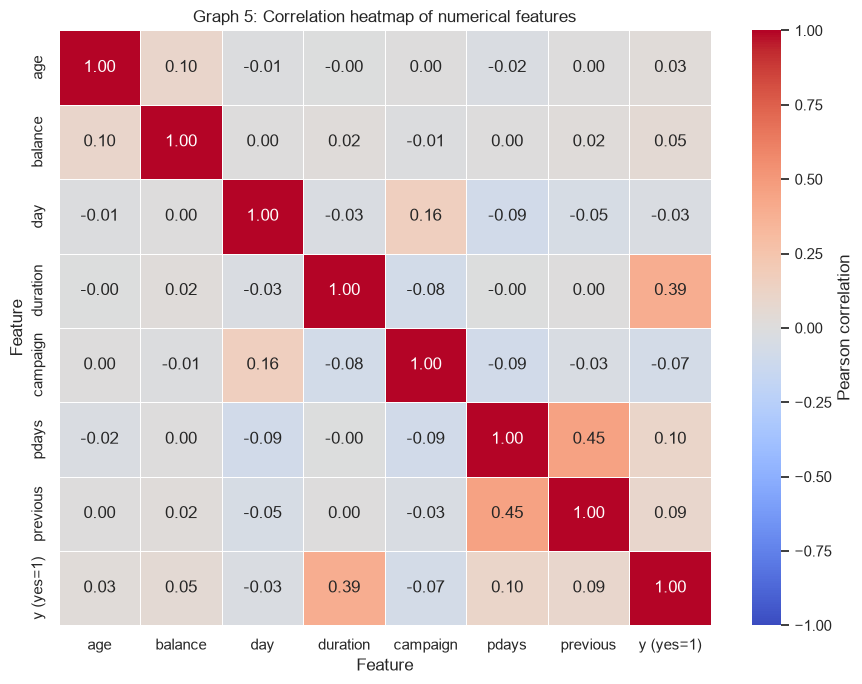

Correlation with the target (sorted by absolute strength):
duration    0.395
pdays       0.104
previous    0.093
campaign   -0.073
balance     0.053
day        -0.028
age         0.025


In [20]:
# Graph 5: Correlation heatmap of numerical features (target added as 0/1 to see its linear relationship)
corr_df = df_clean[num_cols].copy()
corr_df["y (yes=1)"] = (df_clean["y"] == "yes").astype(int)
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Graph 5: Correlation heatmap of numerical features")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

print("Correlation with the target (sorted by absolute strength):")
print(corr["y (yes=1)"].drop("y (yes=1)").sort_values(key=abs, ascending=False).round(3).to_string())

**What Graph 5 shows.** Each cell is the Pearson correlation between two numerical columns (+1 = move together, −1 = move opposite, 0 = no *linear* relationship). The last row/column adds the target as 0/1.
Correlation measures only linear association and **does not prove cause and effect**. Strongly correlated input features (e.g. `pdays` and `previous`) carry overlapping information, which matters mainly for linear models.

In [ ]:
# Graph 6: Subscription outcome by job category
job_stats = (df_clean.groupby("job")["y"]
             .agg(customers="size", subscribers=lambda s: (s == "yes").sum()))
job_stats["subscription_rate_%"] = (job_stats["subscribers"] / job_stats["customers"] * 100).round(2)
job_order_count = job_stats.sort_values("customers", ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.countplot(data=df_clean, y="job", hue="y", order=job_order_count, hue_order=["no", "yes"],
              palette={"no": "#9ecae1", "yes": "#fd8d3c"}, ax=axes[0])
axes[0].set_title("Graph 6a: Subscription outcome by job (counts)")
axes[0].set_xlabel("Number of customers")
axes[0].set_ylabel("Job category")
axes[0].legend(title="Subscribed (y)")

rate_sorted = job_stats["subscription_rate_%"].sort_values(ascending=False)
sns.barplot(x=rate_sorted.values, y=rate_sorted.index, hue=rate_sorted.index, palette="viridis", legend=False, ax=axes[1])
axes[1].axvline(100 * (df_clean["y"] == "yes").mean(), color="red", linestyle="--", label="Overall rate")
axes[1].set_title("Graph 6b: Subscription rate by job (%)")
axes[1].set_xlabel("Subscription rate (%)")
axes[1].set_ylabel("Job category")
axes[1].legend()
plt.tight_layout()
plt.show()

print(job_stats.sort_values("subscription_rate_%", ascending=False).to_string())

**What Graph 6 shows.** Left: for every job type, how many customers said *no* vs *yes*. Right: the **rate** of *yes* inside each job type, compared with the overall rate (dashed red line).
Counts are needed as well as rates: a high rate in a very small group (see the `customers` column in the table) is less reliable than a modest rate in a large group.

In [ ]:
# Graph 7: Subscription rate by month
month_stats = (df_clean.groupby("month")["y"]
               .agg(customers="size", subscribers=lambda s: (s == "yes").sum()))
month_stats["subscription_rate_%"] = (month_stats["subscribers"] / month_stats["customers"] * 100).round(2)
month_stats = month_stats.reindex([m for m in months_valid if m in month_stats.index])

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=month_stats.index, y=month_stats["subscription_rate_%"], hue=month_stats.index,
            palette="crest", legend=False, ax=ax)
ax.axhline(100 * (df_clean["y"] == "yes").mean(), color="red", linestyle="--", label="Overall rate")
for i, (rate, n) in enumerate(zip(month_stats["subscription_rate_%"], month_stats["customers"])):
    ax.text(i, rate + 0.5, f"n={n:,}", ha="center", fontsize=8)
ax.set_title("Graph 7: Subscription rate by month of last contact")
ax.set_xlabel("Month of last contact")
ax.set_ylabel("Subscription rate (%)")
ax.legend()
plt.tight_layout()
plt.show()

print(month_stats.to_string())

**What Graph 7 shows.** The percentage of contacted customers who subscribed, month by month (calendar order), with the number of contacts `n` above each bar and the overall average as a dashed line.
Months with very few contacts can have unstable rates. Month may reflect *when* campaigns happened (and who was targeted then), not that the month itself causes subscriptions.

## 9. Feature engineering

All transformations applied to build `processed_bank_marketing.csv` are listed here and printed in the transformation log below.

| # | Transformation | Reason |
|---|----------------|--------|
| 1 | Duplicate rows removed **only if found** (count reported in Section 7) | Avoid counting the same record twice |
| 2 | `y` converted to binary: `yes = 1`, `no = 0` | Models need numeric labels |
| 3 | **`duration` dropped from the inputs** | **Data-leakage prevention** (see below) |
| 4 | New feature `previously_contacted` = 1 if `pdays != -1` else 0 | Gives the `-1` sentinel a clear meaning: "not contacted before" |
| 5 | New feature `days_since_prev_contact` = `pdays` if contacted before, else 0 | Removes the misleading numeric value `-1` (it would look like "1 day *before* 0" to the scaler). The raw `pdays` column is then dropped because its information is now fully captured by features 4 and 5 |
| 6 | New feature `balance_negative` = 1 if `balance < 0` | Overdrawn accounts may behave differently from positive balances |
| 7 | New categorical feature `age_group` (≤24, 25–34, 35–44, 45–54, 55–64, 65+) | Lets models capture non-linear age effects (very young and older customers) |
| 8 | `"unknown"` values **kept** as a normal category | They are real values in the dataset, not empty cells |
| 9 | Outliers **kept** | Plausible real values (Section 7) |

**Scaling and one-hot encoding are NOT applied here.** They are done later *inside the pipeline* and fitted **only on the training data**, which prevents data leakage.

### Why `duration` is excluded (data leakage)
`duration` is the length of the **last phone call**. It is only known **after** the call has happened — and a long call usually means the customer was interested.
If we kept it, the model would "cheat" by using information that does not exist at the moment we must decide *whom to call*, giving unrealistically good scores.
Since our goal is to **predict before contacting a customer**, `duration` must not be an input. (The UCI documentation itself notes this for realistic predictive models.)
Section 22 includes an optional experiment that measures how much the score would be inflated if `duration` were included.

In [ ]:
transformation_log = []

df_fe = df_clean.copy()
transformation_log.append(f"Duplicate rows removed: {dup_count}")

# Target -> binary
df_fe["y_binary"] = df_fe["y"].map({"yes": 1, "no": 0})
assert df_fe["y_binary"].notna().all(), "Unexpected target value found"
transformation_log.append("Target y encoded: yes=1, no=0")

# pdays sentinel handling
df_fe["previously_contacted"] = (df_fe["pdays"] != -1).astype(int)
df_fe["days_since_prev_contact"] = df_fe["pdays"].where(df_fe["pdays"] != -1, 0)
transformation_log.append("Created previously_contacted (pdays != -1) and days_since_prev_contact (pdays, or 0 if never contacted)")

# Negative balance flag
df_fe["balance_negative"] = (df_fe["balance"] < 0).astype(int)
transformation_log.append("Created balance_negative (balance < 0)")

# Age groups (stored as plain text categories; NaN would stay NaN and be imputed in the pipeline)
df_fe["age_group"] = pd.cut(df_fe["age"], bins=[0, 24, 34, 44, 54, 64, 150],
                            labels=["<=24", "25-34", "35-44", "45-54", "55-64", "65+"]).astype("object")
transformation_log.append("Created age_group from age")

# Leakage prevention and sentinel column removal
columns_to_drop = ["duration", "pdays", "y"]
processed = df_fe.drop(columns=columns_to_drop).rename(columns={"y_binary": "y"})
transformation_log.append("Dropped duration (post-call information -> leakage), pdays (replaced by two engineered features) and the text target (replaced by binary y)")
transformation_log.append("Kept 'unknown' categories and all outliers")

print("Transformation log:")
for i, t in enumerate(transformation_log, 1):
    print(f" {i}. {t}")

print("\nProcessed dataset shape:", processed.shape)
print("Columns:", processed.columns.tolist())
processed.head()

In [ ]:
# Save the processed dataset SEPARATELY (the original bank-full.csv is never written to)
assert PROCESSED_PATH.name != DATA_PATH.name
processed.to_csv(PROCESSED_PATH, index=False)

reloaded = pd.read_csv(PROCESSED_PATH)
print("Saved:", PROCESSED_PATH, "->", reloaded.shape)
print("Target column is binary:", sorted(reloaded["y"].unique().tolist()))
print("'duration' present in processed file:", "duration" in reloaded.columns)

## 10. Train-test split

* 80% of the data for **training**, 20% for **testing**.
* **Stratified** split: both parts keep the same `yes/no` proportion as the full data (important with imbalanced classes).
* `random_state=42` so the split is identical every time.
* The **test set stays untouched** until the final evaluation. No model selection or hyper-parameter choice uses it.

In [ ]:
X = processed.drop(columns=["y"])     # the target is NEVER an input feature
y = processed["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(f"Subscription rate  full: {y.mean():.4f} | train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")
assert "y" not in X_train.columns and "duration" not in X_train.columns

## 11. Data preprocessing pipeline

Columns are identified **programmatically** (by data type), then processed by a `ColumnTransformer`:

| Column type | Step 1 | Step 2 |
|-------------|--------|--------|
| Numerical | `SimpleImputer(strategy="median")` | `StandardScaler()` |
| Categorical | `SimpleImputer(strategy="most_frequent")` | `OneHotEncoder(handle_unknown="ignore")` |

* The imputers are a safety net for unexpected missing values (this dataset has none).
* `handle_unknown="ignore"` means a category never seen in training does not crash prediction (it becomes all zeros).
* The preprocessor is placed **inside a `Pipeline`** with the model. When we call `pipeline.fit(X_train, y_train)`, medians, means, standard deviations and categories are learned **from the training data only**, and are merely *applied* to the test data. That is how we prevent data leakage.
* Tree-based models do not need scaling, but using one identical preprocessor for all three models keeps the comparison fair and simple.

In [ ]:
def build_preprocessor(X_ref):
    # Identify column types programmatically
    numeric_features = X_ref.select_dtypes(include="number").columns.tolist()
    categorical_features = [c for c in X_ref.columns if c not in numeric_features]

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features),
    ]), numeric_features, categorical_features

preprocessor, numeric_features, categorical_features = build_preprocessor(X_train)
print("Numerical features :", numeric_features)
print("Categorical features:", categorical_features)

# Demonstration only: fit a COPY on the training data to see the transformed shape
_demo = clone(preprocessor).fit(X_train)
print("\nTransformed training matrix shape:", _demo.transform(X_train).shape,
      "(rows, numeric columns + one-hot columns)")

### Models and hyper-parameters (chosen in advance, not tuned on the test set)

| Model | Main settings | Why |
|-------|---------------|-----|
| Logistic Regression | `max_iter=1000`, `class_weight="balanced"` | Simple, fast, interpretable baseline |
| Decision Tree | `max_depth=6`, `min_samples_leaf=50`, `class_weight="balanced"` | Limiting depth/leaf size prevents memorising the training data (overfitting) |
| Random Forest | `n_estimators=300`, `max_depth=12`, `min_samples_leaf=10`, `class_weight="balanced_subsample"` | Many different trees voting together; usually more accurate and stable than one tree |

**Handling class imbalance:** `class_weight` makes mistakes on the rare `yes` class cost more during training, so the model does not simply ignore it.
All models use `random_state=42`.

In [ ]:
model_definitions = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced",
                                              random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                            class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=10,
                                            class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=RANDOM_STATE),
}

def make_pipeline(model_name):
    # A fresh, unfitted copy of preprocessor + model
    return Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model_definitions[model_name])),
    ])

trained = {}   # will hold the fitted pipelines (fitted on training data only)

## 12. Logistic Regression training

Logistic Regression computes a weighted sum of the input features and turns it into a probability between 0 and 1 using the sigmoid (S-shaped) function. If the probability is ≥ 0.5 it predicts `yes`.

In [ ]:
import time
t0 = time.time()
trained["Logistic Regression"] = make_pipeline("Logistic Regression").fit(X_train, y_train)
print(f"Logistic Regression trained on {len(X_train):,} rows in {time.time()-t0:.1f}s")

## 13. Decision Tree training

A Decision Tree asks a sequence of yes/no questions about the features (e.g. *"was the previous campaign a success?"*) and ends in a leaf that gives the prediction. It is easy to explain but can overfit if allowed to grow too deep.

In [ ]:
t0 = time.time()
trained["Decision Tree"] = make_pipeline("Decision Tree").fit(X_train, y_train)
print(f"Decision Tree trained on {len(X_train):,} rows in {time.time()-t0:.1f}s")

## 14. Random Forest training

A Random Forest builds many decision trees, each on a random sample of the rows and a random subset of the features, and lets them **vote**. Averaging many different trees reduces overfitting compared with a single tree.

In [ ]:
t0 = time.time()
trained["Random Forest"] = make_pipeline("Random Forest").fit(X_train, y_train)
print(f"Random Forest trained on {len(X_train):,} rows in {time.time()-t0:.1f}s")

In [ ]:
# Robustness check: unexpected missing values and an unseen category must not crash prediction
probe = X_test.head(3).copy()
probe.loc[probe.index[0], "balance"] = np.nan          # unexpected missing number
probe.loc[probe.index[1], "job"] = "astronaut"          # category never seen in training
probe.loc[probe.index[2], "education"] = np.nan        # unexpected missing category
for name, pipe in trained.items():
    p = pipe.predict_proba(probe)[:, 1]
    print(f"{name:20s} probabilities for the 3 stress-test rows: {np.round(p, 3)}")

## 15. Model evaluation

All models are now evaluated **once** on the held-out **test set** (20% of the data, never used for fitting).

### Metrics in beginner-friendly language
Imagine the bank phones customers and a model tells it *"this person will say yes"*.

* **Accuracy** – out of *all* predictions, how many were correct? Easy to understand, but **misleading when one class dominates**.
* **Precision** – out of the customers the model *said would subscribe*, how many really did? High precision = few wasted calls.
* **Recall** (sensitivity) – out of the customers who *really subscribed*, how many did the model find? High recall = few missed customers.
* **F1-score** – a single number that balances precision and recall (their harmonic mean). It is low if either one is low.
* **ROC-AUC** – how well the model **ranks** customers: the probability that a random subscriber gets a higher score than a random non-subscriber (0.5 = guessing, 1.0 = perfect).
* **Average precision (AP)** – the area under the precision-recall curve; it focuses on the rare `yes` class and is more informative than ROC-AUC when classes are imbalanced (the random-guess level equals the share of `yes` customers).

Precision, recall and F1 below are for the **positive class (`yes`)** at the default decision threshold of 0.5.

In [ ]:
# Reference point: a baseline that ignores all features
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
d_pred = dummy.predict(X_test)
d_proba = dummy.predict_proba(X_test)[:, 1]
print("Baseline (always predicts the majority class 'no'):")
print(f"  Accuracy = {accuracy_score(y_test, d_pred):.4f} | Recall = {recall_score(y_test, d_pred, zero_division=0):.4f} "
      f"| ROC-AUC = {roc_auc_score(y_test, d_proba):.4f} | AP = {average_precision_score(y_test, d_proba):.4f}")
print("-> High accuracy but it finds no subscribers at all, which is why accuracy alone is not enough.")

In [ ]:
def evaluate_model(name, pipe, X_eval, y_eval):
    y_pred = pipe.predict(X_eval)
    y_proba = pipe.predict_proba(X_eval)[:, 1]
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred, zero_division=0),
        "Recall": recall_score(y_eval, y_pred, zero_division=0),
        "F1-score": f1_score(y_eval, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, y_proba),
        "Average Precision": average_precision_score(y_eval, y_proba),
    }
    return row, y_pred, y_proba

predictions = {}
rows = []
for name, pipe in trained.items():
    row, y_pred, y_proba = evaluate_model(name, pipe, X_test, y_test)
    rows.append(row)
    predictions[name] = {"y_pred": y_pred, "y_proba": y_proba}

results_df = pd.DataFrame(rows).set_index("Model")
print("Model comparison table (held-out test set):")
results_df.round(4)

In [ ]:
# Classification report for every model
for name in trained:
    print("=" * 62)
    print(f"Classification report: {name}")
    print("=" * 62)
    print(classification_report(y_test, predictions[name]["y_pred"],
                                target_names=["no (0)", "yes (1)"], digits=4))

## 16. Model comparison graphs

In [ ]:
# Graph 8: Model performance comparison bar chart
plot_df = results_df.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="Set2", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_title("Graph 8: Model performance comparison on the test set")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Score (0 to 1)")
ax.set_ylim(0, 1.1)
ax.legend(title="Model", loc="upper right", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

**What Graph 8 shows.** For every metric, one bar per model (higher = better). Compare bars **within the same metric**.
Notice that metrics can rank the models differently: for example a model can have the highest accuracy but a low recall. Which metric matters most depends on the business goal (find as many subscribers as possible vs. avoid wasted calls).
The exact numbers are the labels on the bars and in the table in Section 15.

## 17. Confusion matrices

In [ ]:
# Graph 9: Confusion matrix for each model
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred["y_pred"])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted no", "Predicted yes"], yticklabels=["Actual no", "Actual yes"])
    ax.set_title(f"Graph 9: Confusion matrix - {name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
plt.tight_layout()
plt.show()

cm_table = []
for name, pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred["y_pred"]).ravel()
    cm_table.append({"Model": name, "True Neg": tn, "False Pos": fp, "False Neg": fn, "True Pos": tp})
pd.DataFrame(cm_table).set_index("Model")

**What Graph 9 shows.** Each square counts test customers:
* **Top-left (True Negative):** actually *no*, predicted *no* ✔
* **Top-right (False Positive):** actually *no*, predicted *yes* ✘ → a wasted call
* **Bottom-left (False Negative):** actually *yes*, predicted *no* ✘ → a missed subscriber
* **Bottom-right (True Positive):** actually *yes*, predicted *yes* ✔

Precision = TP / (TP + FP) and recall = TP / (TP + FN), so these four numbers (also in the table below the graph) explain the precision and recall values.

## 18. ROC and precision-recall curves

In [ ]:
colors = {"Logistic Regression": "#1b9e77", "Decision Tree": "#d95f02", "Random Forest": "#7570b3"}

# Graph 10: ROC curves
fig, ax = plt.subplots(figsize=(7, 6))
for name, pred in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, pred["y_proba"])
    ax.plot(fpr, tpr, color=colors[name], lw=2, label=f"{name} (AUC = {results_df.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guessing (AUC = 0.500)")
ax.set_title("Graph 10: ROC curves of the three models")
ax.set_xlabel("False positive rate (wasted calls among actual 'no')")
ax.set_ylabel("True positive rate (recall among actual 'yes')")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**What Graph 10 shows.** The ROC curve plots recall (true-positive rate) against the false-positive rate while the decision threshold is moved from strict to lenient.
A curve closer to the **top-left corner** is better; the diagonal dashed line is random guessing. The area under each curve (AUC) is given in the legend.

In [ ]:
# Graph 11: Precision-recall curves
baseline = y_test.mean()
fig, ax = plt.subplots(figsize=(7, 6))
for name, pred in predictions.items():
    prec, rec, _ = precision_recall_curve(y_test, pred["y_proba"])
    ax.plot(rec, prec, color=colors[name], lw=2, label=f"{name} (AP = {results_df.loc[name, 'Average Precision']:.3f})")
ax.axhline(baseline, color="k", linestyle="--", lw=1, label=f"Random guessing (precision = {baseline:.3f})")
ax.set_title("Graph 11: Precision-recall curves of the three models")
ax.set_xlabel("Recall (share of real subscribers found)")
ax.set_ylabel("Precision (share of predicted subscribers who are real)")
ax.set_ylim(0, 1.02)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**What Graph 11 shows.** The trade-off between precision and recall. Moving right (finding more real subscribers) usually lowers precision (more wasted calls).
A curve that stays **higher and further right** is better. The dashed line is what a random model would achieve (the share of subscribers in the test set). Because `yes` is rare, this graph is often more informative than the ROC curve for this dataset.

## 19. Cross-validation

**Five-fold stratified cross-validation on the training data only.** The training set is split into 5 parts; each part is used once as a validation fold while the model trains on the other 4. This gives 5 scores per model, so we can see both the **average** performance and the **stability** (standard deviation).
The whole pipeline (preprocessing + model) is re-fitted inside every fold, so there is no leakage. The test set is not involved.

Model selection: the "best" model is chosen using the **cross-validated ROC-AUC (training data)**, not the test set.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc", "average_precision": "average_precision"}

cv_raw = {}
cv_rows = []
for name in model_definitions:
    scores = cross_validate(make_pipeline(name), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_raw[name] = scores
    row = {"Model": name}
    for m in scoring:
        vals = scores[f"test_{m}"]
        row[m] = f"{vals.mean():.4f} +/- {vals.std():.4f}"
    cv_rows.append(row)

print("5-fold stratified CV on the training set (mean +/- standard deviation):")
cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table

In [ ]:
# Numeric means for selection and plotting
cv_means = pd.DataFrame({name: {m: cv_raw[name][f"test_{m}"].mean() for m in scoring} for name in cv_raw}).T
cv_stds = pd.DataFrame({name: {m: cv_raw[name][f"test_{m}"].std() for m in scoring} for name in cv_raw}).T

best_model_name = cv_means["roc_auc"].idxmax()
print("Cross-validated mean ROC-AUC per model:")
print(cv_means["roc_auc"].round(4).to_string())
print(f"\nSelected model (highest mean CV ROC-AUC on the training data): {best_model_name}")

# Graph: CV comparison
fig, ax = plt.subplots(figsize=(13, 6))
metrics_to_plot = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]
x = np.arange(len(metrics_to_plot))
width = 0.25
for i, name in enumerate(cv_means.index):
    ax.bar(x + (i - 1) * width, cv_means.loc[name, metrics_to_plot], width,
           yerr=cv_stds.loc[name, metrics_to_plot], capsize=3, label=name, color=colors[name])
ax.set_xticks(x)
ax.set_xticklabels(["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "Avg. precision"])
ax.set_title("Cross-validation comparison (5-fold stratified, training data; error bars = 1 std)")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Mean score across folds")
ax.set_ylim(0, 1.05)
ax.legend(title="Model")
plt.tight_layout()
plt.show()

**What this graph shows.** The average score of each model across the 5 validation folds, with error bars showing how much the score varied between folds (small bars = stable model).
Comparing these averages with the test-set results in Section 15 is a useful sanity check: if cross-validation and test scores are close, the model is **not just memorising** the training data.

## 20. Feature importance (Random Forest)

In [ ]:
rf_pipe = trained["Random Forest"]
feature_names = rf_pipe.named_steps["preprocessor"].get_feature_names_out()
importances = rf_pipe.named_steps["model"].feature_importances_
assert len(feature_names) == len(importances)

fi = pd.DataFrame({"feature": feature_names, "importance": importances})
fi["feature"] = fi["feature"].str.replace("num__", "", regex=False).str.replace("cat__", "", regex=False)
fi_top = fi.sort_values("importance", ascending=False).head(15)

# Graph 12: Random Forest feature importance
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=fi_top, x="importance", y="feature", hue="feature", palette="viridis", legend=False, ax=ax)
ax.set_title("Graph 12: Random Forest feature importance (top 15 encoded features)")
ax.set_xlabel("Importance (mean decrease in impurity)")
ax.set_ylabel("Feature (one-hot columns are shown as column_value)")
plt.tight_layout()
plt.show()
fi_top.reset_index(drop=True).round(4)

In [ ]:
# Graph 12b: importance summed back to the ORIGINAL columns (one-hot dummies of the same column are added up)
def original_column(encoded_name):
    for c in categorical_features:
        if encoded_name.startswith(c + "_"):
            return c
    return encoded_name

fi["original_feature"] = fi["feature"].apply(original_column)
fi_orig = (fi.groupby("original_feature")["importance"].sum().sort_values(ascending=False).head(12).reset_index())

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=fi_orig, x="importance", y="original_feature", hue="original_feature", palette="mako", legend=False, ax=ax)
ax.set_title("Graph 12b: Random Forest importance grouped by original column (top 12)")
ax.set_xlabel("Summed importance")
ax.set_ylabel("Original column")
plt.tight_layout()
plt.show()
fi_orig.round(4)

**What Graph 12 shows.** How much each input feature helped the forest reduce impurity (make cleaner yes/no splits), averaged over all trees; the values add up to 1. Graph 12b adds the one-hot columns back together so each *original* column gets one score.

**Careful interpretation.** Importance shows what the model *used*, **not what causes** a customer to subscribe. Impurity-based importance also tends to favour numeric features with many distinct values (such as `balance` or `age`) over binary ones.

## 21. Sample prediction

This is a **demonstration on historical data**. We pick customers from the held-out **test set**, show their input features, and compare the model's prediction with what actually happened.
The predicted probability is the model's *estimate based on patterns in past data*. It is **not a guarantee** about any real customer and **not evidence that any feature causes** subscription.
The selected (best by cross-validation) model is used, with the default threshold of 0.5.

In [ ]:
def demo_prediction(position, model_name=None):
    # position = row number inside X_test
    model_name = model_name or best_model_name
    pipe = trained[model_name]
    sample = X_test.iloc[[position]]
    actual = int(y_test.iloc[position])
    proba = float(pipe.predict_proba(sample)[0, 1])
    pred = int(pipe.predict(sample)[0])
    label = {1: "yes", 0: "no"}
    print(f"Model used: {model_name}")
    print(f"Test-set row (original index {sample.index[0]}):")
    display(sample.T.rename(columns={sample.index[0]: "value"}))
    print(f"Model-estimated probability of subscription : {proba:.1%}")
    print(f"Predicted label                             : {label[pred]}")
    print(f"Actual label (from the dataset)             : {label[actual]}")
    print("Prediction is", "CORRECT" if pred == actual else "WRONG", "for this customer.")

rng = np.random.default_rng(RANDOM_STATE)

# Example A: a randomly chosen test customer
pos_random = int(rng.integers(0, len(X_test)))
print("########## Example A: random test customer ##########")
demo_prediction(pos_random)

In [ ]:
# Example B: a randomly chosen test customer who ACTUALLY subscribed (to see how the model treats real subscribers)
yes_positions = np.flatnonzero(y_test.to_numpy() == 1)
pos_yes = int(rng.choice(yes_positions))
print("########## Example B: random test customer who actually subscribed ##########")
demo_prediction(pos_yes)
print("\nReminder: this is a demonstration on historical records, not a guarantee about a real customer.")

## 22. Results and discussion

In [ ]:
# Everything printed here is computed from the objects above (nothing is typed in by hand)
print("TEST-SET RESULTS")
display(results_df.round(4))

print("\nBest model per test metric:")
for m in results_df.columns:
    print(f"  {m:18s}: {results_df[m].idxmax():20s} ({results_df[m].max():.4f})")

print(f"\nModel selected by cross-validated ROC-AUC (training data only): {best_model_name}")

print("\nCV mean vs. test score (ROC-AUC) - a large gap would signal overfitting or leakage:")
gap = pd.DataFrame({"CV ROC-AUC (train)": cv_means["roc_auc"], "Test ROC-AUC": results_df["ROC-AUC"]})
gap["difference"] = gap["Test ROC-AUC"] - gap["CV ROC-AUC (train)"]
display(gap.round(4))

In [ ]:
# Optional experiment: how much would the score be INFLATED if the leaky column `duration` were used?
# (Logistic Regression only; same split; for explanation purposes - NOT part of the final model.)
X_train_leak = X_train.assign(duration=df_fe.loc[X_train.index, "duration"])
X_test_leak = X_test.assign(duration=df_fe.loc[X_test.index, "duration"])
pre_leak, _, _ = build_preprocessor(X_train_leak)
lr_leak = Pipeline([("preprocessor", pre_leak),
                    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))]).fit(X_train_leak, y_train)
auc_leak = roc_auc_score(y_test, lr_leak.predict_proba(X_test_leak)[:, 1])
auc_clean = results_df.loc["Logistic Regression", "ROC-AUC"]
print(f"Logistic Regression ROC-AUC WITHOUT duration (our model)   : {auc_clean:.4f}")
print(f"Logistic Regression ROC-AUC WITH duration (leaky, unrealistic): {auc_leak:.4f}")
print(f"Inflation caused by the leaky column: {auc_leak - auc_clean:+.4f}")

### Discussion

*The numbers quoted below come from the run of this notebook with `random_state=42` (scikit-learn 1.8). The tables printed above are the authoritative source; with other library versions the values can differ slightly.*

**1. Accuracy is misleading here.** A baseline that always answers "no" scores **88.3% accuracy** but finds **0** subscribers (recall 0). All three trained models have *lower* accuracy (76.6%–82.3%) than this useless baseline, because `class_weight` deliberately trades some accuracy for the ability to detect the rare `yes` class. That is why precision, recall, F1, ROC-AUC and average precision are reported.

**2. Comparison of the three models (test set).**

| Observation | Evidence |
|---|---|
| **Random Forest** gave the best ranking quality and best balance | Highest ROC-AUC (0.798), average precision (0.442) and F1 (0.438); precision 0.343 (essentially tied with the Decision Tree, 0.343) |
| **Logistic Regression** finds the most subscribers but wastes the most calls | Highest recall (0.626) but lowest precision (0.278) and lowest accuracy (0.766) |
| **Decision Tree** has the highest accuracy but the weakest ranking | Accuracy 0.823, but lowest recall (0.558), ROC-AUC (0.757) and average precision (0.355) |

**3. Why Random Forest is selected.** The model was chosen using **cross-validated ROC-AUC on the training data only** (Random Forest 0.788 vs 0.766 for Logistic Regression and 0.748 for the Decision Tree). ROC-AUC is threshold-independent and measures how well a model ranks likely subscribers above unlikely ones, which is what a call-prioritisation list needs. The held-out test set confirms the same ordering for ROC-AUC, average precision and F1.

**4. No sign of overfitting or leakage.** Test ROC-AUC is within about 0.01 of the cross-validation average for every model (the test value is slightly higher), and the fold-to-fold standard deviations are small (Section 19). The pipeline fits all preprocessing on training data only.

**5. What the Random Forest result means in practice.** In the confusion matrix, the Random Forest identifies 640 of the 1,058 real subscribers in the test set (recall 60.5%) but also flags 1,226 customers who did not subscribe (precision 34.3%). The overall subscription rate is 11.7%, so the customers the model flags are about **2.9 times** more likely to subscribe than a randomly chosen customer. The model is useful for *prioritising* calls, but it is far from perfect: roughly two out of three flagged customers still say no.

**6. Exploratory findings (descriptive, not causal).**
* *Job:* students (28.7%) and retired customers (22.8%) have the highest subscription rates; blue-collar (7.3%) the lowest; the overall rate is 11.7%.
* *Month:* May has by far the most contacts (13,766) and one of the lowest rates (6.7%), whereas March, September, October and December have rates above 40% but each with fewer than 750 contacts, so those rates are based on small groups and may reflect which customers were targeted in those months.
* *Age:* the typical age of subscribers and non-subscribers is similar (median 38 vs 39), but subscribers are more spread out, with more young and older customers.
* *Correlation:* among numerical features, `duration` has the strongest linear link to the target (0.40), all others are below about 0.11 in absolute value — which is exactly why including `duration` would be so tempting and so misleading.

**7. Feature importance.** The most important original columns for the Random Forest are `poutcome` (outcome of the previous campaign; `poutcome_success` is the single strongest encoded feature), `month`, `contact` and `housing`, followed by `balance`, `age` and `day`. Several of these (`month`, `day`, `contact`) describe *how and when the bank contacted the customer* rather than who the customer is, so the model partly learns the bank's past campaign process. Importance is not causation.

**8. Cost of the data-leakage decision.** In the optional experiment, adding `duration` to Logistic Regression raises ROC-AUC from 0.774 to 0.909 (+0.135). That jump is not real predictive power for choosing whom to call, because the call length is only known after the call. Excluding it keeps the project honest.

## 23. Conclusion

* We built a complete, reproducible supervised-learning pipeline on the genuine UCI Bank Marketing data (45,211 records) to predict term-deposit subscription **before** a customer is contacted.
* The data had no empty cells and no duplicate rows. `"unknown"` values and outliers were kept because they are valid information; the `pdays = -1` sentinel was converted into a clear `previously_contacted` flag.
* The leaky column `duration` was excluded; the optional experiment showed it would have inflated Logistic Regression's ROC-AUC by about 0.13.
* Three models (Logistic Regression, Decision Tree, Random Forest) were trained with class weighting and evaluated with accuracy, precision, recall, F1, ROC-AUC, average precision, confusion matrices, ROC/PR curves and 5-fold stratified cross-validation.
* **Random Forest** was selected (best cross-validated ROC-AUC) and also had the best test ROC-AUC, average precision and F1. Logistic Regression finds the most subscribers (highest recall) at the price of many wasted calls, and the Decision Tree is the easiest to explain but ranks customers least well.
* All models beat a no-skill baseline in ranking ability but remain modest in absolute terms (best precision ≈ 0.34 at the default threshold). They are useful for **prioritising** customers, not for deciding with certainty.

**Possible future work:** tune hyper-parameters with cross-validation on the training set, choose the decision threshold using the bank's real cost of a call versus the value of a deposit, try gradient-boosting models, and test on newer data.

### Viva cheat-sheet (likely questions)
1. **Why not use accuracy only?** Because 88% of customers say "no"; always predicting "no" gives 88% accuracy and finds nobody.
2. **What is data leakage and where did you avoid it?** Using information not available at prediction time. We dropped `duration`, and we fitted imputers/scaler/encoder on the training data only (inside a `Pipeline`).
3. **Why stratified split?** To keep the same yes/no proportion in train and test.
4. **Why were the test data not used to pick the model?** To keep the final evaluation unbiased; the model was selected via cross-validation on the training data.
5. **Precision vs recall?** Precision = how many predicted "yes" were right; recall = how many real "yes" we found.
6. **Why ROC-AUC and average precision?** They judge how well the model ranks customers independent of one threshold; AP focuses on the rare positive class.
7. **Why does Random Forest usually beat a single tree?** Many decorrelated trees voting reduces variance (overfitting).
8. **Does a high feature importance mean cause and effect?** No — it only shows what the model relied on.

## 24. Limitations

1. **Historical, single-bank data.** The records come from one Portuguese bank's campaigns; the model may not transfer to other banks, countries or years (the data cover roughly 2008–2010, during a financial crisis).
2. **Predictive, not causal.** Feature importance and probabilities describe patterns in past data. They do not show that changing a feature (e.g. calling in a certain month) *causes* more subscriptions.
3. **No `duration`.** Excluding the leaky column makes the task realistic but harder; scores are therefore much lower than in papers that use it.
4. **Imbalanced classes and a fixed threshold.** Results are reported at the default 0.5 threshold. A bank could choose a different threshold depending on the cost of a call versus the value of a subscription; this project does not model costs.
5. **Limited tuning.** Hyper-parameters were set sensibly in advance (not tuned on the test set) but were not searched exhaustively; a grid/random search on the training data could improve the models.
6. **Limited feature information.** There is no information about income, product history, or time-series behaviour; `month`/`day` are only the last contact's calendar position.
7. **Customer-level fairness and privacy.** Using attributes such as age, marital status or education in real marketing decisions raises fairness concerns; this project is for learning only.
8. **Single random split.** Metrics from one 80/20 split carry some randomness; cross-validation (Section 19) reduces but does not remove this uncertainty.
9. **Possible differences across library versions.** Results are reproducible with the fixed seed on the same library versions; other versions may differ slightly.

## 25. Dataset citation

Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing*. UCI Machine Learning Repository. DOI: [10.24432/C5K306](https://doi.org/10.24432/C5K306)

Dataset page: <https://archive.ics.uci.edu/dataset/222/bank+marketing>

Related paper: S. Moro, P. Cortez and P. Rita. *A Data-Driven Approach to Predict the Success of Bank Telemarketing.* Decision Support Systems, Elsevier, 62:22-31, June 2014.

In [ ]:
# Final integrity check: the original dataset file must be byte-for-byte unchanged by this notebook
raw_hash_after = file_sha256(DATA_PATH)
print("SHA-256 before:", raw_hash_before)
print("SHA-256 after :", raw_hash_after)
print("bank-full.csv unchanged:", raw_hash_before == raw_hash_after)
assert raw_hash_before == raw_hash_after